In [1]:
# carregando os pacotes que vamos utilziar para análise de dados
import pandas as pd
import statistics as st
from scipy import stats
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import binom, nbinom, poisson, uniform, expon, norm, t, ttest_1samp, shapiro
import statsmodels.stats.proportion as prop

In [3]:
# Abrir o banco de dados
bd = pd.read_csv('BD_Alunos.csv',sep=';',encoding='unicode_escape')

In [4]:
# Mostra o banco de dados
bd.head(5)

,Registros,Curso,Genero,Idade,Trabalha,Cursou_EnsinoMedio,Horas_EstudoSemana,Conhecimento_Matematica
0,1,Engenharia,Masculino,17,Não,Escola Pública Normal,10,4
1,2,Engenharia,Masculino,18,Não,Escola Pública Normal,6,3
2,3,Engenharia,Masculino,20,Não,Escola Pública Normal,8,3
3,4,Engenharia,Masculino,18,Não,Escola Técnica,24,4
4,5,Engenharia,Masculino,23,Sim,Escola Militar,3,1


In [5]:
# Verificar quantidade de linhas e colunas
bd.shape

(295, 8)

In [6]:
# informações a respeito do banco de dados
bd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 295 entries, 0 to 294
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype 
---  ------                   --------------  ----- 
 0   Registros                295 non-null    int64 
 1   Curso                    295 non-null    object
 2   Genero                   295 non-null    object
 3   Idade                    295 non-null    int64 
 4   Trabalha                 295 non-null    object
 5   Cursou_EnsinoMedio       295 non-null    object
 6   Horas_EstudoSemana       295 non-null    int64 
 7   Conhecimento_Matematica  295 non-null    int64 
dtypes: int64(4), object(4)
memory usage: 18.6+ KB


In [7]:
# Verificar se tem registros sem preenchimento
bd.isnull().sum()

,0
Registros,0
Curso,0
Genero,0
Idade,0
Trabalha,0
Cursou_EnsinoMedio,0
Horas_EstudoSemana,0
Conhecimento_Matematica,0


In [9]:
# Transformação de variável - int (discreta) para float (contínua)
bd.Horas_EstudoSemana = bd.Horas_EstudoSemana.astype(float)

In [10]:
print("Média =",round(bd.Idade.mean(),2))

Média = 18.76


In [11]:
# Medidas de posição
print("Média = ",round(bd.Idade.mean(),2))
print("Mediana = ",round(bd.Idade.median(),2))
print("Moda = ",round(bd.Idade.mode(),2))

Média =  18.76
Mediana =  18.0
Moda =  0    18
Name: Idade, dtype: int64


In [12]:
# Medidas de variabilidade ou dispersão
print("Mínimo = ",bd.Idade.min())
print("Máximo = ",bd.Idade.max())
print("Amplitude = ",bd.Idade.max()-bd.Idade.min())
print("Variância = ",round(bd.Idade.var(),2))
print("Desvio-padrão = ",round(bd.Idade.std(),2))

Mínimo =  16
Máximo =  41
Amplitude =  25
Variância =  9.5
Desvio-padrão =  3.08


In [14]:
# Função para o cálculo do Coeficiente de Variação
def cv(n):
  return round(st.stdev(n)/st.mean(n)*100, 2)

In [15]:
# Calculou o coeficiente de variação
print('CV(%) = ', cv(bd.Idade))

CV(%) =  16.44


In [21]:
# Estatísticas gerais
bd.describe()

,Registros,Idade,Horas_EstudoSemana,Conhecimento_Matematica
count,295.00000,295.000000,295.000000,295.000000
mean,148.00000,18.755932,13.305085,3.213559
std,85.30338,3.082994,12.452979,0.836143
min,1.00000,16.000000,1.000000,1.000000
25%,74.50000,17.000000,4.000000,3.000000
50%,148.00000,18.000000,10.000000,3.000000
75%,221.50000,19.000000,20.000000,4.000000
max,295.00000,41.000000,60.000000,5.000000


In [22]:
# Construir as classes para uma variável quantitativa
classes = [0, 18, 25, 30, 35, 42]
rotulos = ['0-|18', '18-|25', '25-|30', '30-|35', '35-|41']
classes = pd.cut(x=bd.Idade, bins=classes, labels=rotulos)
bd['Classe'] = classes
bd.head()

,Registros,Curso,Genero,Idade,Trabalha,Cursou_EnsinoMedio,Horas_EstudoSemana,Conhecimento_Matematica,Classe
0,1,Engenharia,Masculino,17,Não,Escola Pública Normal,10.0,4,0-|18
1,2,Engenharia,Masculino,18,Não,Escola Pública Normal,6.0,3,0-|18
2,3,Engenharia,Masculino,20,Não,Escola Pública Normal,8.0,3,18-|25
3,4,Engenharia,Masculino,18,Não,Escola Técnica,24.0,4,0-|18
4,5,Engenharia,Masculino,23,Sim,Escola Militar,3.0,1,18-|25


In [24]:
Freq = bd.Classe.value_counts()
Percentual = round(bd.Classe.value_counts(sort=False,normalize=True)*100,1)
tabela_Idade = pd.DataFrame({'Frequência':Freq,'Percentual':Percentual})
tabela_Idade.rename_axis('Idade',axis='columns',inplace=True)
tabela_Idade

Idade,Frequência,Percentual
Classe,,
0-|18,218,73.9
18-|25,64,21.7
25-|30,9,3.1
30-|35,2,0.7
35-|41,2,0.7


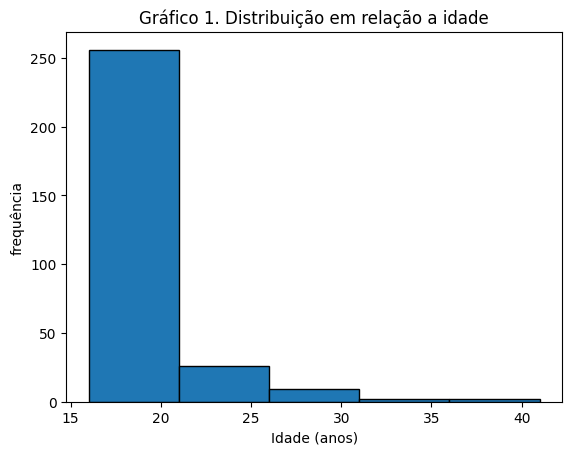

In [25]:
# Histograma
plt.hist(bd.Idade, bins=5, edgecolor='black')
plt.title('Gráfico 1. Distribuição em relação a idade')
plt.xlabel('Idade (anos)')
plt.ylabel('frequência')
#plt.grid(axis='y', linestyle='--', alpha=0.7)  # opicional
plt.show()

In [26]:
# Mostrar as categorias de uma variável
bd.Genero.unique()

array(['Masculino', 'Feminino'], dtype=object)

In [27]:
# Mostrar as frequências absoliutas simples
bd.Genero.value_counts()

,count
Genero,
Masculino,212
Feminino,83


In [29]:
# Atribuir a tabela a um objeto
freq_Genero = bd.Genero.value_counts()

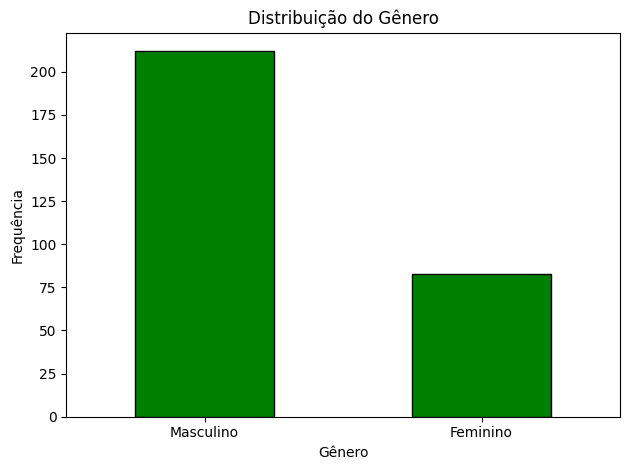

In [32]:
# Construir o gráfico de barras
freq_Genero.plot(kind='bar', color='skyblue', edgecolor='black')
plt.title('Distribuição do Gênero')
plt.xlabel('Gênero')
plt.ylabel('Frequência')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

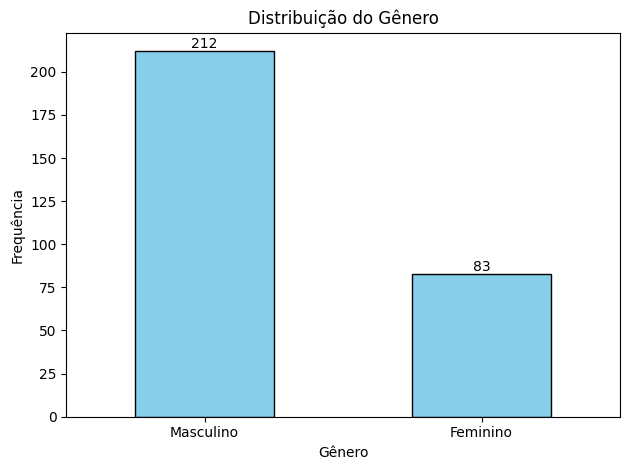

In [33]:
# Adiciona os rótulos sobre as barras
ax = freq_Genero.plot(kind='bar', color='skyblue', edgecolor='black')
ax.bar_label(ax.containers[0], label_type='edge', fontsize=10)
plt.title('Distribuição do Gênero')
plt.xlabel('Gênero')
plt.ylabel('Frequência')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [34]:
# Mostrar as frequências relativa simples
round(bd.Genero.value_counts(normalize=True)*100,1)

,proportion
Genero,
Masculino,71.9
Feminino,28.1


In [35]:
# Tabela simples completa para variável qualitativa
Freq = bd.Genero.value_counts()
Percentual = round(bd.Genero.value_counts(normalize=True)*100,1)
Tabela_genero = pd.DataFrame({'Frequência':Freq,'Percentual':Percentual})
Tabela_genero.rename_axis('Gênero',axis='columns',inplace=True)
Tabela_genero

Gênero,Frequência,Percentual
Genero,,
Masculino,212,71.9
Feminino,83,28.1


In [36]:
# Tabela com duas variáveis qualitativas
tab_Sexo_curso=pd.crosstab(bd.Curso, bd.Genero)
tab_Sexo_curso

Genero,Feminino,Masculino
Curso,,
Engenharia,59,183
Licenciatura em Computação,6,22
Meteorologia,18,7


In [37]:
# Comparar média de uma variável quantitativa em relação a uma qualitativa.
Tab_HorasEstudo_Trabalho = round(bd.groupby('Trabalha').Horas_EstudoSemana.median(),2)
Tab_HorasEstudo_Trabalho

,Horas_EstudoSemana
Trabalha,
Não,10.0
Sim,7.0


In [41]:
# Comparar média de uma variável quantitativa em relação a uma qualitativa.
Tab_HorasEstudo_Genero = round(bd.groupby('Genero').Horas_EstudoSemana.mean(),2)
Tab_HorasEstudo_Genero

,Horas_EstudoSemana
Genero,
Feminino,13.47
Masculino,13.24


/tmp/ipykernel_2571/2674398208.py:1: FutureWarning: 

The `ci` parameter is deprecated. Use `errorbar='sd'` for the same effect.

  sns.pointplot(x='Trabalha',y='Horas_EstudoSemana',data=bd,ci='sd')


<Axes: xlabel='Trabalha', ylabel='Horas_EstudoSemana'>

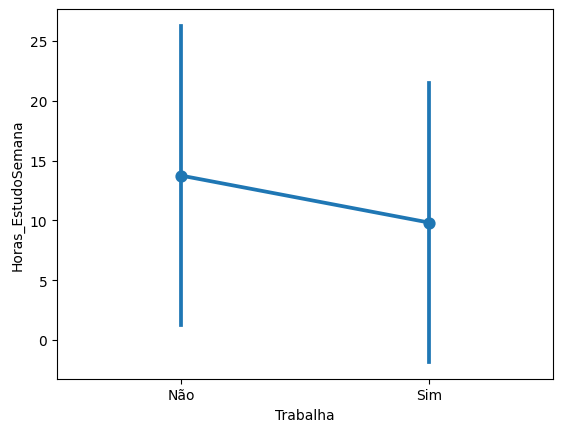

In [42]:
sns.pointplot(x='Trabalha',y='Horas_EstudoSemana',data=bd,ci='sd')

<Axes: xlabel='Horas_EstudoSemana', ylabel='Trabalha'>

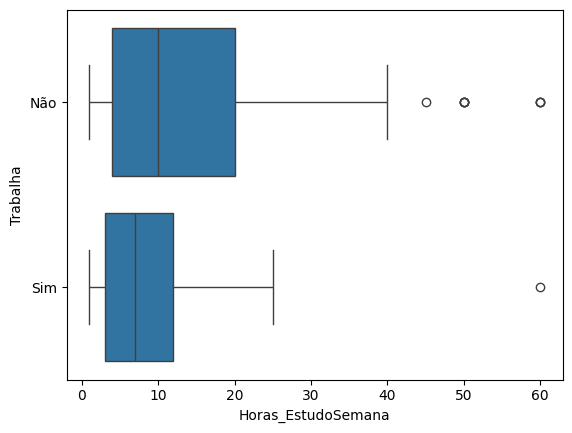

In [43]:
sns.boxplot(x='Horas_EstudoSemana',y='Trabalha', data=bd)

In [44]:
# Retira uma amostra aleatória simples do banco de dados com base e uma semente.
amostra=bd.sample(n=120,random_state=234)
amostra.head()

,Registros,Curso,Genero,Idade,Trabalha,Cursou_EnsinoMedio,Horas_EstudoSemana,Conhecimento_Matematica,Classe
44,45,Engenharia,Masculino,18,Não,Escola Pública Normal,1.0,5,0-|18
53,54,Engenharia,Masculino,19,Não,Escola Técnica,20.0,3,18-|25
263,264,Engenharia,Feminino,18,Não,Escola Particular,5.0,3,0-|18
127,128,Engenharia,Masculino,18,Não,Escola Militar,5.0,3,0-|18
83,84,Meteorologia,Masculino,18,Não,Escola Pública Normal,2.0,2,0-|18


In [45]:
# número de registros no novo banco
amostra.shape

(120, 9)

In [46]:
# Tabela Curso por Sexo
tab_eng_sexo=pd.crosstab(amostra.Curso, amostra.Genero)
tab_eng_sexo

Genero,Feminino,Masculino
Curso,,
Engenharia,30,75
Licenciatura em Computação,1,7
Meteorologia,4,3


In [47]:
# Análise de uma variável quantitativa em relação a uma variável qualitativa
Tab_HorasEstudo_Trabalho = bd.groupby('Trabalha')['Horas_EstudoSemana'].mean()
print(round(Tab_HorasEstudo_Trabalho,2))

Trabalha
Não    13.74
Sim     9.82
Name: Horas_EstudoSemana, dtype: float64


In [48]:
# Selecionar só Engenharia
eng=amostra[amostra.Curso=='Engenharia']
eng.shape

(105, 9)

In [49]:
# Tabela simples
eng.Curso.value_counts()

,count
Curso,
Engenharia,105


In [50]:
# Selecionar Engenharia e sexo feminino
dados_eng_f=amostra[(amostra.Curso=="Engenharia") & (amostra.Genero=="Feminino")]
dados_eng_f.shape

(30, 9)

**Inferência**


In [51]:
# Intervalo de Confiança para Proporção
# inf, sup = prop.proportion_confint (x,n, alpha=0.05, method='normal')
print("n =", len(bd.Trabalha))
print(bd.Trabalha.value_counts(normalize=True)*100)
inf,sup=prop.proportion_confint(len(bd[bd.Trabalha=="Sim"]),len(bd.Trabalha),alpha=0.05,method='normal')
print('e =',round((sup-inf)/2*100,2),"%")
print("IC95%(",round(inf*100,2),';',round(sup*100,2),')')

n = 295
Trabalha
Não    88.813559
Sim    11.186441
Name: proportion, dtype: float64
e = 3.6 %
IC95%( 7.59 ; 14.78 )


In [52]:
# Intervalo de Confiança para Média quando a variância é desconhecida
# inf,sup = t.interval(k, n-1, media, dp/np.sqrt(n))
n = len(bd.Horas_EstudoSemana)
media=bd.Horas_EstudoSemana.mean()
dp=bd.Horas_EstudoSemana.std()
Conf = 0.95 # Confiança
inf,sup = t.interval(Conf, n-1, media, dp/np.sqrt(n))
print("Média = ",round(media,2))
print('e =',round((media-inf),2))
print("IC95%(",round(inf,2),';',round(sup,2),")")

Média =  13.31
e = 1.43
IC95%( 11.88 ; 14.73 )


In [53]:
# média de horas de estudo por semana:
print("Média = ",round(bd.Horas_EstudoSemana.mean(),2))

Média =  13.31


In [ ]:
# Teste de Hipóteses para Média
# ttest_1samp(dados, Ho, teste bicaudal)
Ho = input("Hipótese nula")
Ho = float(Ho)
t,p = ttest_1samp(bd.Horas_EstudoSemana, Ho, alternative='two-sided') # Caso seja unilateral a direita alternative='greater', caso contrário alternative = 'less'.
print('t=%.3f, p=%.3f' % (t, p))
if p > 0.05:
   print ("Conclusão: aceita-se Ho ao nível de 5% de significância")
else:
   print ("Conclusão: rejeita-se Ho ao nível de 5% de significância")

In [ ]:
# Proporção dos alunos em relação ao curso:
print(round(bd.Curso.value_counts(normalize=True)*100),1)

In [ ]:
# Teste bicaudal para proporção
Po = input('Valor de Ho (%):')
Po=float(Po)/100
n = input('Tamanho da amostra:')
n=int(n)
x = input('Valor de X:')
x=int(x)
alfa_perc = input('Valor de alfa em %:')
alfa=float(alfa_perc)/100
z, p = prop.proportions_ztest(x, n, Po, alternative='two-sided') # Caso seja unilateral a direita alternative='greater', caso contrário alternative = 'less'

print('z= %0.3f, p= %0.3f' % (z, p))
if p > alfa:
   print ("Conclusão: aceita-se Ho, ou seja, a proproção é estatisticamente igual a",round(Po*100,2),"%", "ao nível de 5% de significância")
else:
   print ("Conclusão: rejeita-se Ho, ou seja, a proproção é estatisticamente diferente de",round(Po*100,2),"%", "ao nível de 5% de significância")